# دمای یک میله با DeepONet و قرارداد موتور جدید

این نوت‌بوک از پکیج نصب‌شده و مسیر import سازگار `contracts` استفاده می‌کند. دو MLP جدا داریم:
branch فقط دمای مرز چپ `T_left` را می‌گیرد؛ trunk فقط مختصات `x` را می‌گیرد.
یک Model جدا با حاصل‌ضرب داخلیِ دو بردار، دما را تولید می‌کند:

$$T_\theta(T_{left},x)=\sum_{k=1}^{K}branch_k(T_{left})\,trunk_k(x).$$

مسئله رسانش پایای یک‌بعدی با رسانندگی واحد است:

$$\frac{dT}{dx}+q=0,\qquad T(0)=T_{left},\qquad 0\le x\le1.$$

برای اینکه ورودی branch فقط `T_left` باشد، **شار در همهٔ سناریوها ثابت و برابر یک** است.
بنابراین جواب تحلیلی `T = T_left - x` است. مقدار `q` فقط برای دادهٔ مرجع و residual
فیزیکی استفاده می‌شود و ورودی شبکه‌ها نیست. برای شار متغیر باید ورودی مدل گسترش یابد.

**حد اجرایی:** مشتق مرتبهٔ اول با AD محلی اجرا می‌شود. آموزش این مثال همچنان با دادهٔ
جواب تحلیلی است؛ در پایان residual فیزیکی و backward از آن نیز اجرا می‌شوند، ولی
همگرایی آموزش فقط با loss فیزیکی ادعا نمی‌شود. شرط مرزی از داده‌ها یاد گرفته می‌شود؛
هیچ تبدیل سخت یا skip connection به خروجی اضافه نمی‌کنیم.


## ۱. آماده‌سازی

به PyTorch، matplotlib، nbformat و IPython نیاز است. برای اجرای سلول‌ها خودِ nbformat
لازم نیست. Graphviz اختیاری است؛ نمودار جایگزین از همان گراف واقعی Solver رسم می‌شود.
هیچ فایل `solver_graph.py` یا بستهٔ اضافیِ مشتق‌گیری لازم نیست.

In [1]:
from pathlib import Path
import shutil
import tempfile
from textwrap import fill

import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import SVG, display

# Install the project in this kernel environment: pip install -e ".[notebook]"
from contracts import (
    Derivative, PartialDerivative, TotalDerivative,
    Model, Quantity, Signature, Solver, Value,
)

torch.manual_seed(7)
# Small CPU matrices do not need a large thread pool.
torch.set_num_threads(1)

## ۲. کمیت‌ها و مشتق نمادین

شکل ذاتی کمیت از محورهای نمونه جداست. `T_left` و `x` اسکالرند؛ خروجی هر MLP
یک بردار ویژگی است. Quantityها وابسته به تعداد سناریوها و نقاط نیستند.
برای تمرکز روی ترکیب مدل‌ها از Quantity و geometry=None استفاده می‌کنیم.

| کمیت | شکل ذاتی | محورهای مقدار |
|---|---|---|
| مکان x | `()` | point |
| دمای مرز T_left | `()` | scenario |
| شار ثابت q | `()` | هیچ‌کدام |
| ویژگی branch | `(8,)` | scenario |
| ویژگی trunk | `(8,)` | point |
| دما و residual | `()` | scenario, point |
| مشتق مکانی درخواستی | `()` | scenario, point |
| loss نهایی | `()` | هیچ‌کدام |


In [ ]:
LATENT = 8
x = Quantity("x")
left_temperature = Quantity("T_left")
heat_flux = Quantity("q")
branch_features = Quantity("branch_features", (LATENT,))
trunk_features = Quantity("trunk_features", (LATENT,))
temperature = Quantity("T")
residual = Quantity("heat_residual")
loss = Quantity("loss")

# The derivative's source is the composed DeepONet, not only its final model.
dT_dx = TotalDerivative(temperature, x)
assert isinstance(dT_dx, Derivative)
assert dT_dx.shape == temperature.shape + x.shape == ()

# An optional partial request; holding preserves the producer training graph.
partial_example = PartialDerivative(temperature, x, holding=(branch_features,))
print(dT_dx)


## ۳. branch، trunk و حاصل‌ضرب داخلی

کلاس MLP برای هر دو شبکه استفاده می‌شود ولی دو instance با پارامترهای جدا می‌سازیم.
هر evaluate یک اسکالر می‌گیرد و بردار ویژگی می‌دهد. تمام Signatureهای این بخش
از محور نمونه خالی‌اند؛ در نتیجه forward روی محورهای اضافه vmap می‌کند.

branch روی S دمای مرز و trunk روی P نقطه اجرا می‌شود. مدل InnerProduct بردارهای
آن‌ها را به S×P دما تبدیل می‌کند؛ ورودی‌ها را دستی تکرار یا به `(S,P)` گسترش نمی‌دهیم.


In [3]:
class MLP(Model):
    geometry = None

    def __init__(self, input_quantity, output_quantity):
        super().__init__()
        if input_quantity.shape != () or len(output_quantity.shape) != 1:
            raise ValueError("This MLP maps one scalar to one feature vector")
        self.input_quantity = input_quantity
        self.output_quantity = output_quantity
        self._signature = Signature({input_quantity: ()}, {output_quantity: ()})
        self.network = nn.Sequential(
            nn.Linear(1, 16), nn.Tanh(),
            nn.Linear(16, 16), nn.Tanh(),
            nn.Linear(16, output_quantity.shape[0]),
        )

    @property
    def signature(self):
        return self._signature

    def evaluate(self, values):
        # A scalar becomes a length-one feature vector for nn.Linear.
        scalar = values[self.input_quantity]
        return {self.output_quantity: self.network(scalar.unsqueeze(-1))}


class InnerProduct(Model):
    geometry = None
    signature = Signature(
        {branch_features: (), trunk_features: ()}, {temperature: ()}
    )

    def evaluate(self, values):
        # Only intrinsic features are summed, not points or scenarios.
        return {temperature: torch.dot(values[branch_features], values[trunk_features])}


## ۴. residual و loss

Residual مقدار مشتق را مثل هر کمیت ورودی دیگر درخواست می‌کند؛ قرار نیست خودش
از `autograd.grad` استفاده کند. Solver باید مشتق را از مسیر تولید دما به دست بیاورد.
Loss کل سناریوها و نقاط را مصرف می‌کند و یک اسکالر می‌دهد.

In [4]:
class HeatResidual(Model):
    geometry = None
    signature = Signature({dT_dx: (), heat_flux: ()}, {residual: ()})

    def evaluate(self, values):
        # Conductivity is one: q = -dT/dx.
        return {residual: values[dT_dx] + values[heat_flux]}


class MeanSquaredResidual(Model):
    geometry = None
    signature = Signature({residual: ("scenario", "point")}, {loss: ()})

    def evaluate(self, values):
        return {loss: values[residual].square().mean()}


branch = MLP(left_temperature, branch_features)
trunk = MLP(x, trunk_features)
inner_product = InnerProduct()
residual_model = HeatResidual()
loss_model = MeanSquaredResidual()

# One Solver with five models, deliberately supplied out of dependency order.
solver = Solver([loss_model, residual_model, inner_product, trunk, branch],
                outputs=loss, derivative_backend="autograd")
assert set(solver.inputs) == {heat_flux, x, left_temperature}
assert dT_dx not in solver.inputs  # Derivatives are internal graph nodes.
assert branch.signature.inputs == {left_temperature: ()}
assert trunk.signature.inputs == {x: ()}


## ۵. برنامهٔ مشتق و نمودار DeepONet

گره‌های MLP با یال‌های `branch_features` و `trunk_features` از هم مشخص‌اند؛ شبکه‌ها
در InnerProduct به هم می‌رسند. مشتق خروجی همین ترکیب به residual داده می‌شود.
برنامهٔ مشتق به همهٔ مدل‌های لازم در این ترکیب اشاره می‌کند؛ wrt=x در ورودی trunk است.
گرهٔ نارنجی درخواست مشتق است؛ backend آن از گراف همان forward استفاده می‌کند.


In [ ]:
plan = solver.derivative_plans[dT_dx]
print("Producer:", type(solver.models[plan.producer_index]).__name__)
print("Source model indices:", plan.model_indices)
print("Function inputs:", [q.name for q in plan.function_inputs])
print("Structurally depends on x:", plan.depends_on_wrt)
assert solver.models[plan.producer_index] is inner_product
assert {id(solver.models[i]) for i in plan.model_indices} == {id(branch), id(trunk), id(inner_product)}

mermaid_source = solver.to_mermaid(direction="TB")
dot_source = solver.to_dot(direction="TB", title="DeepONet temperature | local reverse-mode AD")
assert 'd0 -->|' in mermaid_source and '| m1' in mermaid_source
print(mermaid_source)


In [ ]:
def draw_contract_graph(solver):
    # Read dependency metadata; no model or derivative executes during drawing.
    external = {q: f"i{i}" for i, q in enumerate(solver.inputs)}
    labels = {node: q.name for q, node in external.items()}
    kinds = {node: "input" for node in external.values()}
    levels = {node: 0 for node in external.values()}
    edges = []

    for kind, key in solver._ordered:
        node = f"m{key}" if kind == "model" else f"d{solver.derivatives.index(key)}"
        dependencies = solver._node_dependencies[(kind, key)]
        sources = [solver._source_node(q, external) for q in dependencies]
        levels[node] = 1 + max((levels[source] for source in sources), default=0)
        labels[node] = (type(solver.models[key]).__name__ + " / " + ", ".join(q.name for q in solver.models[key].outputs)) if kind == "model" else key.name
        kinds[node] = kind
        if kind == "model":
            edges.extend((solver._source_node(q, external), node, q.name) for q in dependencies)
        else:
            edges.extend((solver._source_node(q, external), node, f"{role}: {q.name}")
                         for q, role in solver._derivative_graph_inputs(key))

    for i, quantity in enumerate(solver.outputs):
        node = f"o{i}"
        source = solver._source_node(quantity, external)
        labels[node], kinds[node], levels[node] = quantity.name, "output", levels[source] + 1
        edges.append((source, node, ""))

    positions = {}
    for level in sorted(set(levels.values())):
        members = [node for node in labels if levels[node] == level]
        for i, node in enumerate(members):
            positions[node] = (3.8 * (i - (len(members) - 1) / 2), -2.2 * level)

    fig, ax = plt.subplots(figsize=(12, 10))
    colors = {"input": "#EFF6FF", "model": "#F5F3FF",
              "derivative": "#FFF0D9", "output": "#ECFDF5"}
    for source, target, caption in edges:
        start, end = positions[source], positions[target]
        long_vertical = start[0] == end[0] and levels[target] - levels[source] > 1
        if long_vertical:
            # Route x -> derivative outside the branch/trunk boxes entirely.
            rail = max(px for px, py in positions.values()) + 1.
            ax.plot((start[0], rail, rail),
                    (start[1], start[1] - .6, end[1] + .6),
                    color="#64748B", lw=1, zorder=1)
            ax.annotate("", xy=end, xytext=(rail, end[1] + .6),
                        arrowprops=dict(arrowstyle="->", color="#64748B", shrinkA=0, shrinkB=24),
                        zorder=1)
            caption_x, caption_y = rail + .12, (start[1] + end[1]) / 2
        else:
            ax.annotate("", xy=end, xytext=start,
                        arrowprops=dict(arrowstyle="->", color="#64748B", shrinkA=22, shrinkB=24,
                                        connectionstyle="arc3,rad=0.06"), zorder=1)
            caption_x = (start[0] + end[0]) / 2 + .12 + .03 * (end[1] - start[1])
            caption_y = (start[1] + end[1]) / 2 - .03 * (end[0] - start[0])
        if caption:
            ax.text(caption_x, caption_y, fill(caption, 25), fontsize=8, color="#475569", zorder=2,
                    bbox=dict(facecolor="white", edgecolor="none", alpha=.85))
    for node, (px, py) in positions.items():
        ax.text(px, py, fill(labels[node], 29), ha="center", va="center", fontsize=10,
                bbox=dict(boxstyle="round,pad=.65", facecolor=colors[kinds[node]],
                          edgecolor="#94A3B8"), zorder=3)
    xs, ys = zip(*positions.values())
    ax.set(xlim=(min(xs)-2.5, max(xs)+2.5), ylim=(min(ys)-1, max(ys)+1.2))
    ax.set_title("DeepONet temperature | orange node: local reverse-mode AD", pad=20)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


if shutil.which("dot"):
    graph_path = Path(tempfile.gettempdir()) / "temperature_engine_graph.svg"
    solver.render_graph(graph_path, direction="TB", title="DeepONet temperature | PINN Engine contracts")
    display(SVG(filename=str(graph_path)))
else:
    # Graphviz is optional; the fallback is derived from the same dependency graph.
    draw_contract_graph(solver)

## ۶. دمای مرز به branch، مکان به trunk

چهار دمای مرز و ۲۴ نقطهٔ مشترک داریم. شار یک اسکالر ثابت است و محور سناریو ندارد.
با انتخاب خروجی دما، همان Solver فقط branch، trunk و InnerProduct را اجرا می‌کند.
برابری خروجی با ضرب ماتریسی معمول DeepONet نیز بررسی می‌شود.


In [7]:
S, P = 4, 24
coordinates = torch.linspace(0, 1, P)
boundary_values = torch.tensor([0., 1., .5, -.5])
fixed_flux = torch.tensor(1.)  # Fixed for the whole operator-learning problem.
inputs = {
    left_temperature: Value(boundary_values, "scenario"),
    x: Value(coordinates, "point"),
    heat_flux: Value(fixed_flux),
}

target = boundary_values[:, None] - fixed_flux * coordinates[None, :]
predicted = solver(inputs, outputs=temperature)[temperature]
assert predicted.axes == ("scenario", "point")
assert predicted.tensor.shape == (S, P)

# The graph performs exactly the standard DeepONet branch/trunk product.
with torch.no_grad():
    branch_table = branch.network(boundary_values[:, None])  # (S, K)
    trunk_table = trunk.network(coordinates[:, None])        # (P, K)
    torch.testing.assert_close(predicted.tensor, branch_table @ trunk_table.T)
print("DeepONet output:", predicted.axes, tuple(predicted.tensor.shape))


DeepONet output: ('scenario', 'point') (4, 24)


## ۷. آموزش هر دو شبکه با جواب تحلیلی

optimizer پارامترهای branch و trunk را از همان Solver می‌گیرد. هر دو شبکه از loss
گرادیان دریافت می‌کنند. هیچ مقدار مشتقی دستی وارد نمی‌شود؛ اجرای فیزیکی در بخش بعد نشان داده می‌شود.
دمای مرزی هم این بار از داده‌ها یاد گرفته می‌شود، نه با تبدیل سخت خروجی.


In [8]:
optimizer = torch.optim.Adam(solver.parameters(), lr=.01)
history = []
for step in range(400):
    optimizer.zero_grad(set_to_none=True)
    predicted = solver(inputs, outputs=temperature)[temperature]
    error = Value(predicted.tensor - target, predicted.axes)
    objective = loss_model({residual: error})[loss].tensor
    objective.backward()
    # Both MLPs participate in learning, rather than a single concatenated MLP.
    assert all(parameter.grad is not None for parameter in branch.parameters())
    assert all(parameter.grad is not None for parameter in trunk.parameters())
    optimizer.step()
    history.append(objective.detach().item())

with torch.no_grad():
    fitted = solver(inputs, outputs=temperature)[temperature].tensor
    mse = (fitted - target).square().mean().item()
assert mse < 1e-3, f"The small DeepONet example did not converge: {mse}"
print(f"Initial supervised MSE: {history[0]:.6f}")
print(f"Final supervised MSE:   {mse:.6f}")


Initial supervised MSE: 0.563281
Final supervised MSE:   0.000130


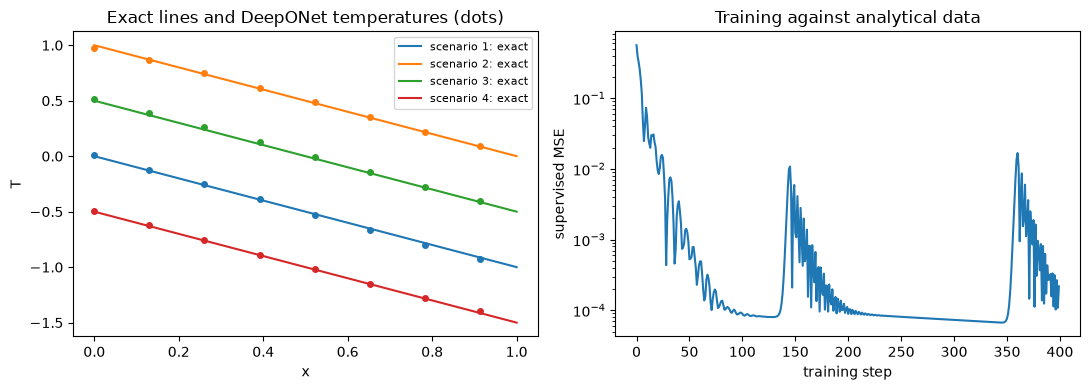

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for scenario in range(S):
    line, = axes[0].plot(coordinates, target[scenario], label=f"scenario {scenario + 1}: exact")
    axes[0].plot(coordinates[::3], fitted[scenario, ::3], "o", color=line.get_color(), ms=4)
axes[0].set(xlabel="x", ylabel="T", title="Exact lines and DeepONet temperatures (dots)")
axes[0].legend(fontsize=8)
axes[1].semilogy(history)
axes[1].set(xlabel="training step", ylabel="supervised MSE", title="Training against analytical data")
fig.tight_layout()
plt.show()

## ۸. مدل وابسته بین نقاط و مرز AD

evaluate می‌تواند کل point را بگیرد و روی همان نقاط خروجی بدهد. اجرای عادی مجاز است.
فقط درخواست AD که به استقلال همین محور نیاز دارد خطا می‌گیرد؛ یک holding مناسب
یا شاخهٔ مستقل از wrt می‌تواند آن مسیر را از مشتق خارج کند.

In [ ]:
centered_x = Quantity("centered_x")

class CenterPoints(Model):
    geometry = None
    signature = Signature({x: "point"}, {centered_x: "point"})

    def evaluate(self, values):
        # The mean couples the outputs, but they still describe the same points.
        return {centered_x: values[x] - values[x].mean()}

coupled_ad = TotalDerivative(centered_x, x)
coupled_solver = Solver([CenterPoints()], outputs=coupled_ad)
coupled_inputs = {x: Value(torch.arange(4.), "point")}

# Ordinary evaluation is legal, even when the Solver also has an AD request.
print("Centered values:", coupled_solver(coupled_inputs, outputs=centered_x)[centered_x].tensor)

try:
    coupled_solver(coupled_inputs)
except NotImplementedError as error:
    assert "non-independent sample axes" in str(error)
    print("Expected AD limitation:", error)
else:
    raise AssertionError("AD must reject the coupled point axis")

## ۹. اجرای مسیر فیزیکی با مشتق محلی

خروجی پیش‌فرض loss از گرهٔ مشتق عبور می‌کند. هر مدل منبع فقط یک بار forward می‌شود
و AD محلی بدون replay از همان گراف استفاده می‌کند. اینجا عدد loss و گرادیان پارامترها
را بررسی می‌کنیم؛ optimizer روی loss فیزیکی اجرا نمی‌شود.

In [ ]:
# Evaluate the actual physics residual and train through its derivative.
optimizer.zero_grad(set_to_none=True)
physics_loss = solver(inputs)[loss].tensor
assert torch.isfinite(physics_loss)
physics_loss.backward()
for network in (branch, trunk):
    gradients = [p.grad for p in network.parameters() if p.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients)
print("Physics residual MSE:", physics_loss.detach().item())


## ۱۰. backendهای آینده

Quantity مشتق و برنامهٔ مسیر، وابسته به autograd نیستند. تفاضل محدود می‌تواند
تابع مسیر را با ورودیِ جابه‌جاشده دوباره اجرا کند و holding را ثابت نگه دارد؛
مشتق طیفی به grid و شرایط مناسب نیاز دارد و Jacobian عمومی هر Quantity را نمی‌دهد.
backendهای غیر AD هنوز پیاده نشده‌اند. جزئیات در `docs/contracts.fa.md` آمده است.

مشتق مرتبهٔ اول، holding و grouping محلی اکنون اجرا می‌شوند؛ مشتق مرتبهٔ بالاتر و
بهینه‌سازی backendهای دیگر باقی‌اند. `torch.compile` جای این تصمیم‌های معنایی را نمی‌گیرد.